# Лабораторная работа №2. Трансформер руками. Токены, векторы, внимание

Ноутбук проходит по частям работы и показывает результаты. Вся логика находится в `run.py`, ноутбук вызывает те же функции.

Части: 1 - свой BPE, 2 - токенизатор Qwen3 и бюджет контекста, 3 - векторы и поиск по корпусу, 4а - на кого смотрит местоимение, 4б - размывание инструкции в длинном контексте. Артефакты записываются в `artifacts/`.

## Подготовка
`FAST = True` включает быстрый режим (проверка, 200 слияний, 60 абзацев, короткие контексты).

In [21]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))               # ноутбук запускается из папки lab02
import run as lab

FAST = False                                      # True - быстрый режим, False - полный прогон для сдачи

text = lab.load_corpus()                          # скачивает корпус, если его ещё нет
words = lab.corpus_words(text)                    # нижний регистр, слова по регулярному выражению
print(f"слов в корпусе: {len(words):,}, уникальных: {len(set(words)):,}")

слов в корпусе: 433,082, уникальных: 48,117


## 1. Свой BPE
Каждое слово разбивается на буквы и получает маркер конца слова `</w>`. Затем многократно ищется самая частая пара соседних символов во всём словаре и сливается в один символ. Порядок слияний важен, сначала сливаются самые частые пары, поэтому частые слова собираются в целые токены, а редкие остаются набором кусков. Слова реже `MIN_FREQ` в обучение не берутся, так как это быстрее. Выученные слияния применяются ко всему корпусу. Сжатие считается как число букв, делённое на число токенов.

In [23]:
bpe = lab.part1_bpe(words, FAST)
s = bpe["stats"]
print(f"слияний: {bpe['num_merges']}, словарь BPE: {bpe['vocab_size']}")
print(f"букв: {s['chars']:,} | слов: {s['words']:,} | токенов BPE: {s['tokens_bpe']:,}")
print(f"токенов на слово: {s['tokens_per_word']} | сжатие относительно букв: {s['compression_vs_chars']}")

print("\nпервые слияния (пара -> новый символ, частота пары в момент слияния):")
for (a, b), c in list(zip(bpe["merges"], bpe["merge_counts"]))[:15]:
    print(f"  {a!r} + {b!r} -> {a + b!r}   {c:,}")

print("\nпримеры разбиения:")
for w, t in bpe["examples"].items():
    print(f"  {w}: {t}")

слияний: 1500, словарь BPE: 1534
букв: 2,245,342 | слов: 433,082 | токенов BPE: 836,998
токенов на слово: 1.9327 | сжатие относительно букв: 2.6826

первые слияния (пара -> новый символ, частота пары в момент слияния):
  'о' + '</w>' -> 'о</w>'   54,000
  'и' + '</w>' -> 'и</w>'   44,842
  'а' + '</w>' -> 'а</w>'   40,120
  'е' + '</w>' -> 'е</w>'   39,329
  'я' + '</w>' -> 'я</w>'   21,814
  'с' + 'т' -> 'ст'   21,488
  'ь' + '</w>' -> 'ь</w>'   20,639
  'а' + 'л' -> 'ал'   18,150
  'т' + 'о' -> 'то'   16,285
  'в' + '</w>' -> 'в</w>'   15,703
  'о' + 'н' -> 'он'   15,556
  'й' + '</w>' -> 'й</w>'   15,114
  'т' + 'о</w>' -> 'то</w>'   14,592
  'м' + '</w>' -> 'м</w>'   14,572
  'п' + 'о' -> 'по'   14,042

примеры разбиения:
  наполеон: ['наполеон</w>']
  сказала: ['сказала</w>']
  неудовольствие: ['не', 'удоволь', 'ствие</w>']


## 2. Токенизатор Qwen3 и бюджет контекста
Функция `count_tokens(text)` считает токены токенизатора `Qwen/Qwen3-0.6B-Base` (byte-level BPE, без служебных токенов). Сравниваем русский абзац из корпуса (слова с 500 по 600) и фиксированный английский абзац. Сколько токенов приходится на слово и сколько слов поместится в контекст из 4096 токенов.

In [27]:
tpw = lab.part2_tokens(words)
print(f"токенизатор: {tpw['tokenizer']}, словарь: {tpw['vocab_size']}, контекст: {tpw['context_tokens']} токенов\n")
print(f"{'язык':<6}{'слов':>6}{'токенов':>9}{'токенов/слово':>15}{'слов в контексте':>18}")
for lang in ("ru", "en"):
    r = tpw[lang]
    print(f"{lang:<6}{r['words']:>6}{r['tokens']:>9}{r['tokens_per_word']:>15.3f}{r['words_in_context']:>18}")
print("\nпервые токены русского абзаца:", tpw["example_ru"][:20])

токенизатор: Qwen/Qwen3-0.6B-Base, словарь: 151669, контекст: 4096 токенов

язык    слов  токенов  токенов/слово  слов в контексте
ru       100      198          1.980              2068
en        70       81          1.157              3539

первые токены русского абзаца: ['х', 'оч', 'ет', ' для', ' благ', 'а', ' мира', ' и', ' что', ' они', ' об', 'ещ', 'али', ' ничего', ' и', ' что', ' об', 'ещ', 'али', ' и']


## 3. Векторы и поиск по корпусу
Корпус режется на абзацы по переводам строки, остаются абзацы длиной от 40 до 120 слов (первые 500, в быстром режиме 60). Абзацы и 12 запросов превращаются в векторы тремя способами, для каждого находятся пять ближайших абзацев по косинусу.

- `static` - среднее входных эмбеддингов Qwen3 по токенам (таблица, контекста нет);
- `contextual` - среднее скрытых состояний последнего слоя Qwen3 (те же токены после внимания);
- `e5` - энкодер `multilingual-e5-small` с префиксами `query: ` и `passage: `, обученный именно под поиск.

recall@5 - доля запросов, у которых правильный абзац (с фразой из таблицы) попал в пятёрку.

In [30]:
res3 = lab.part3_search(text, FAST)
print(f"абзацев: {res3['n_paragraphs']}, k = {res3['k']}\n")
print(f"{'способ':<12}{'recall@5':>10}")
for m, v in res3["recall_at_k"].items():
    print(f"{m:<12}{v:>10.3f}")

print("\nпопал ли правильный абзац в пятёрку (по запросам):")
print(f"{'№':<4}{'static':<9}{'contextual':<12}{'e5':<5}")
for n, it in enumerate(res3["queries"], 1):
    print(f"{n:<4}{str(it['answer_id'] in it['top']['static']):<9}{str(it['answer_id'] in it['top']['contextual']):<12}{str(it['answer_id'] in it['top']['e5']):<5}")

абзацев: 500, k = 5

способ        recall@5
static           0.583
contextual       0.250
e5               0.833

попал ли правильный абзац в пятёрку (по запросам):
№   static   contextual  e5   
1   False    False       False
2   True     False       True 
3   False    True        True 
4   True     False       True 
5   False    False       True 
6   True     False       True 
7   True     True        False
8   False    False       True 
9   True     False       True 
10  False    False       True 
11  True     False       True 
12  True     True        True 


## 4а. На кого смотрит "его"
Модель загружается с `attn_implementation="eager"` и `output_attentions=True`, иначе карты внимания не получить. Для предложения "Врач, после осмотра пациента, сказал, что его анализы готовы.", берётся строка внимания последнего токена местоимения "его" в каждом слое и каждой голове. Выбирается голова, где наибольшая сумма весов приходится на токены слова "пациента".

лучшая голова: слой 3, голова 3
доля внимания 'его' на 'пациента': 0.725
токены: ['В', 'ра', 'ч', ' ос', 'мотр', 'ел', ' паци', 'ента', ' и', ' сказал', ',', ' что', ' его', ' ана', 'ли', 'зы', ' готов', 'ы', '.']


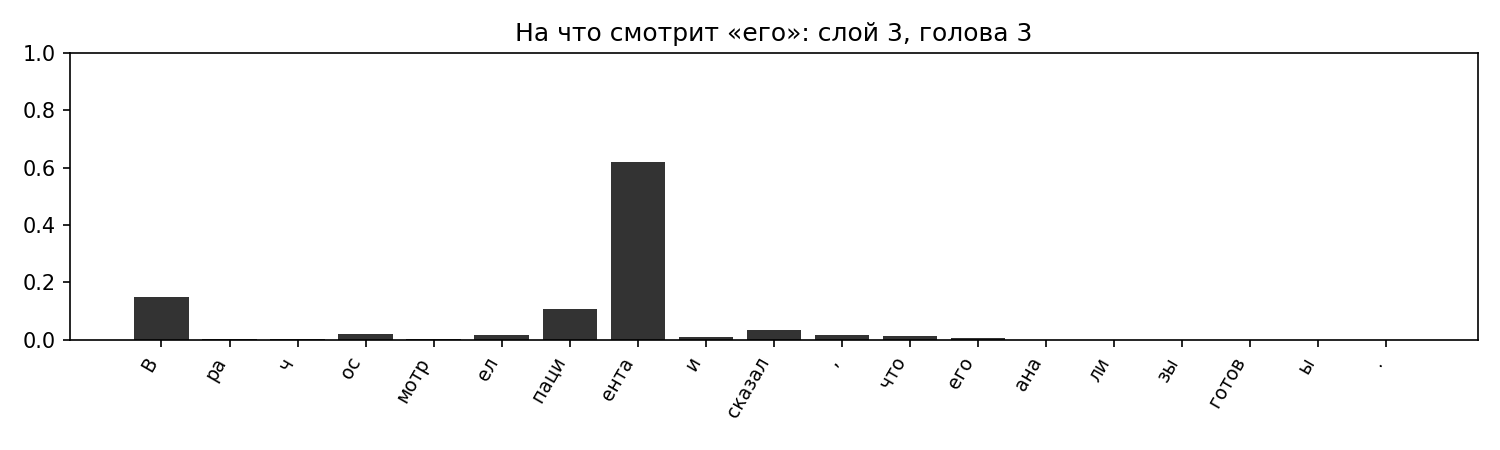

In [35]:
att = lab.part4a_attention()
print(f"лучшая голова: слой {att['best_layer']}, голова {att['best_head']}")
print(f"доля внимания 'его' на 'пациента': {att['share_on_antecedent']:.3f}")
print("токены:", att["tokens"])

from IPython.display import Image, display
display(Image(filename=str(lab.ARTIFACTS / "attention_map.png")))

## 4б. Размывание
Инструкция "Отвечай только по-русски и в конце каждого ответа ставь слово КОНЕЦ.", стоит в начале, за ней идёт текст из корпуса такой длины, чтобы весь вход был ровно 128, 512 и 1024 токена (в быстром режиме 64, 256, 768). Считается, какую долю внимания последний токен (в среднем по слоям и головам) отдаёт токенам инструкции, и сравнивается с долей при равномерном внимании. Первый токен входа в долю не включается, на него модель сбрасывает большую часть внимания при любом тексте (сток, attention sink), его доля записывается отдельно.

 токенов  в инструкции  доля на инструкцию  если бы поровну  на сток
     128            23              0.0213           0.1797    0.489
     512            23              0.0094           0.0449    0.451
    1024            23              0.0027           0.0225    0.411


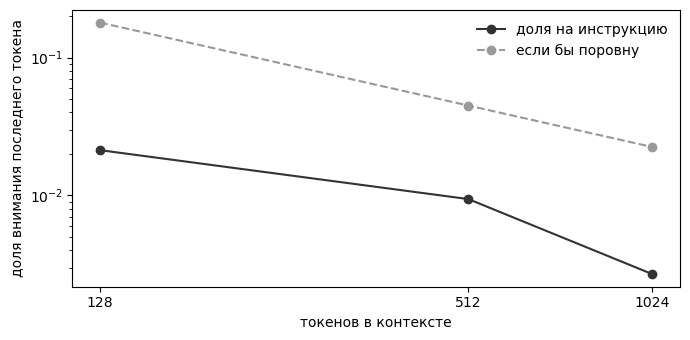

In [40]:
rows = lab.part4b_dilution(words, FAST)
print(f"{'токенов':>8}{'в инструкции':>14}{'доля на инструкцию':>20}{'если бы поровну':>17}{'на сток':>9}")
for r in rows:
    print(f"{r['context_len']:>8}{r['instruction_len']:>14}{r['share_on_instruction']:>20.4f}{r['uniform_share']:>17.4f}{r['sink_share']:>9.3f}")

import matplotlib.pyplot as plt
xs = [r["context_len"] for r in rows]
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(xs, [r["share_on_instruction"] for r in rows], "o-", color="#333333", label="доля на инструкцию")
ax.plot(xs, [r["uniform_share"] for r in rows], "o--", color="#999999", label="если бы поровну")
ax.set_xscale("log", base=2); ax.set_yscale("log")
ax.set_xticks(xs); ax.set_xticklabels(xs)
ax.set_xlabel("токенов в контексте"); ax.set_ylabel("доля внимания последнего токена")
ax.legend(frameon=False); fig.tight_layout(); plt.show()

## Артефакты
Все файлы записаны в `artifacts/` - `bpe.json`, `tokens_per_word.json`, `paragraphs.json`, `search.json`, `attention_map.json`, `attention_map.png`, `dilution.csv`. Тесты читают их из репозитория: из корня репозитория выполните `python -m pytest tests/test_lab02.py -v`.

In [43]:
for p in sorted(lab.ARTIFACTS.iterdir()):
    print(f"{p.name:<24}{p.stat().st_size:>10,} байт")

attention_map.json             744 байт
attention_map.png           36,648 байт
bpe.json                    30,388 байт
dilution.csv                   181 байт
paragraphs.json            393,339 байт
search.json                  4,260 байт
tokens_per_word.json           650 байт
